In [1]:
import zipfile
import os

zip_path = '/content/archive.zip'
extract_path = '/content/extracted_data'

# Extract zip file
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

# List contents of the extracted folder
for root, dirs, files in os.walk(extract_path):
    level = root.replace(extract_path, '').count(os.sep)
    indent = ' ' * 4 * (level)
    print(f'{indent}{os.path.basename(root)}/')
    subindent = ' ' * 4 * (level + 1)
    for f in files[:5]: # Show up to 5 files per directory to keep output clean
        print(f'{subindent}{f}')
    if len(files) > 5:
        print(f'{subindent}... and {len(files) - 5} more files')

extracted_data/
    train/
        benign/
            1123.jpg
            1281.jpg
            392.jpg
            795.jpg
            945.jpg
            ... and 1435 more files
        malignant/
            1123.jpg
            1281.jpg
            392.jpg
            795.jpg
            945.jpg
            ... and 1192 more files
    data/
        train/
            benign/
                1123.jpg
                1281.jpg
                392.jpg
                795.jpg
                945.jpg
                ... and 1435 more files
            malignant/
                1123.jpg
                1281.jpg
                392.jpg
                795.jpg
                945.jpg
                ... and 1192 more files
        test/
            benign/
                323.jpg
                1471.jpg
                993.jpg
                98.jpg
                444.jpg
                ... and 355 more files
            malignant/
                1355.jpg
                421.jpg
     

=== Dataset Distribution ===
   Split      Class  Count
0  Train     benign   1440
1  Train  malignant   1197
2   Test     benign    360
3   Test  malignant    300


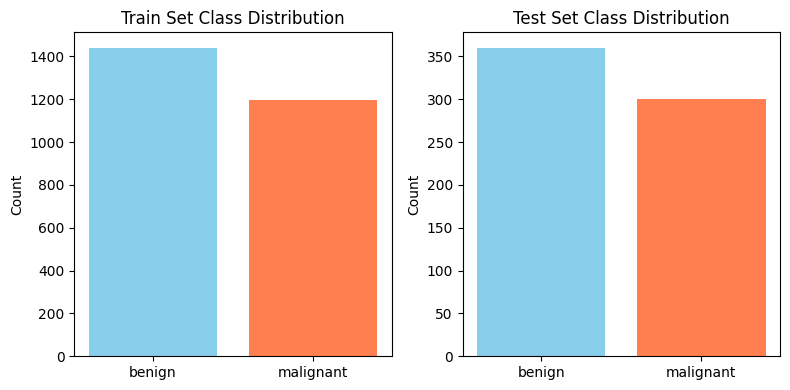

Sample benign image shape: (224, 224, 3) | Data Type: uint8
Sample malignant image shape: (224, 224, 3) | Data Type: uint8


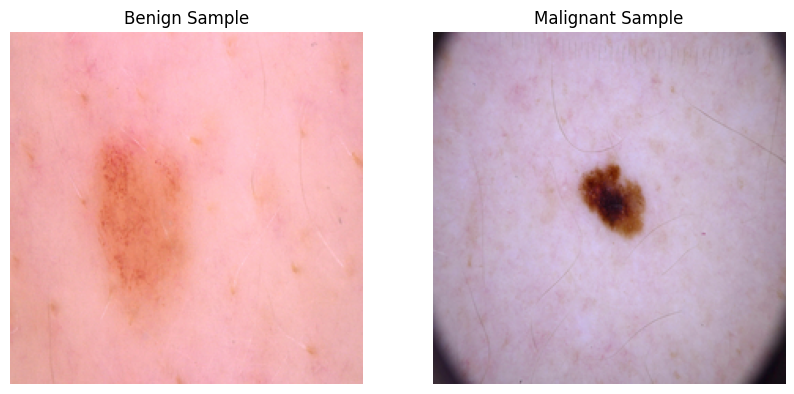

In [2]:
import os
import glob
import pandas as pd
import cv2
import matplotlib.pyplot as plt

base_dir = '/content/extracted_data/data'
train_dir = os.path.join(base_dir, 'train')
test_dir = os.path.join(base_dir, 'test')

# Count images per class
categories = ['benign', 'malignant']
eda_data = []

for split, path in [('Train', train_dir), ('Test', test_dir)]:
    for cat in categories:
        cat_path = os.path.join(path, cat)
        count = len(os.listdir(cat_path))
        eda_data.append({'Split': split, 'Class': cat, 'Count': count})

df_counts = pd.DataFrame(eda_data)
print("=== Dataset Distribution ===")
print(df_counts)

# Visualize class distribution
plt.figure(figsize=(8, 4))
for i, split in enumerate(['Train', 'Test']):
    plt.subplot(1, 2, i+1)
    split_df = df_counts[df_counts['Split'] == split]
    plt.bar(split_df['Class'], split_df['Count'], color=['skyblue', 'coral'])
    plt.title(f'{split} Set Class Distribution')
    plt.ylabel('Count')
plt.tight_layout()
plt.show()

# Load a sample image from each class to inspect dimensions
for cat in categories:
    cat_path = os.path.join(train_dir, cat)
    sample_img_name = os.listdir(cat_path)[0]
    img_path = os.path.join(cat_path, sample_img_name)
    img = cv2.imread(img_path)
    print(f"Sample {cat} image shape: {img.shape} | Data Type: {img.dtype}")

# Plot sample images
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for i, cat in enumerate(categories):
    cat_path = os.path.join(train_dir, cat)
    sample_img_name = os.listdir(cat_path)[0]
    img_path = os.path.join(cat_path, sample_img_name)
    img = cv2.imread(img_path)
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    axes[i].imshow(img_rgb)
    axes[i].set_title(f"{cat.capitalize()} Sample")
    axes[i].axis('off')
plt.show()

In [3]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from sklearn.metrics import classification_report, accuracy_score

# Set random seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)

# Configurations
IMG_HEIGHT, IMG_WIDTH = 128, 128  # Resizing to 128x128 for efficient training in Colab
BATCH_SIZE = 32

# Data Augmentation & Normalization for Training
# We will split the train_dir into 80% Training and 20% Validation
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True,
    validation_split=0.2  # 20% validation split
)

test_datagen = ImageDataGenerator(rescale=1./255)

# Generators
train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    class_mode='binary',
    subset='training',
    seed=42
)

val_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    class_mode='binary',
    subset='validation',
    seed=42
)

test_generator = test_datagen.flow_from_directory(
    test_dir,
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    class_mode='binary',
    shuffle=False
)

# CNN Architecture
model = Sequential([
    Conv2D(32, (3, 3), activation='relu', input_shape=(IMG_HEIGHT, IMG_WIDTH, 3)),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    Conv2D(128, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_cross_entropy' if hasattr(tf.keras.losses, 'binary_cross_entropy') else 'binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

# Train the model
history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=10,
    verbose=1
)

# Predict on the test set
y_pred_prob = model.predict(test_generator)
y_pred = (y_pred_prob > 0.5).astype(int).flatten()
y_true = test_generator.classes

# Output metrics
acc = accuracy_score(y_true, y_pred)
print(f"\nTest Accuracy: {acc:.4f}")
print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=test_generator.class_indices.keys()))

Found 2110 images belonging to 2 classes.
Found 527 images belonging to 2 classes.
Found 660 images belonging to 2 classes.


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,304,769 (12.61 MB)

 Trainable params: 3,304,769 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 90s 1s/step - accuracy: 0.7175 - loss: 0.5380 - val_accuracy: 0.6395 - val_loss: 0.6265
Epoch 2/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 86s 1s/step - accuracy: 0.7645 - loss: 0.4640 - val_accuracy: 0.7457 - val_loss: 0.5195
Epoch 3/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 89s 1s/step - accuracy: 0.7910 - loss: 0.4143 - val_accuracy: 0.6641 - val_loss: 0.5973
Epoch 4/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 85s 1s/step - accuracy: 0.7929 - loss: 0.4096 - val_accuracy: 0.7799 - val_loss: 0.5018
Epoch 5/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 85s 1s/step - accuracy: 0.7953 - loss: 0.4291 - val_accuracy: 0.7609 - val_loss: 0.4866
Epoch 6/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 86s 1s/step - accuracy: 0.8128 - loss: 0.3824 - val_accuracy: 0.6926 - val_loss: 0.5709
Epoch 7/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 141s 1s/step - accuracy: 0.8057 - loss: 0.4060 - val_accuracy: 0.7818 - val_loss: 0.5264
Epoch 8/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 86s 1s/step - accuracy: 0.8171 - loss: 0.3904 - val_accuracy: 0.7306 - val_loss

In [4]:
import pandas as pd

# Map indices back to class names
class_labels = {v: k for k, v in test_generator.class_indices.items()}

# Create a DataFrame with filenames, actual labels, and predicted labels
results_df = pd.DataFrame({
    'File_Path': test_generator.filenames,
    'Actual_Label': [class_labels[y] for y in y_true],
    'Predicted_Label': [class_labels[p] for p in y_pred],
    'Correct_Prediction': y_true == y_pred
})

# Display the first 20 rows of predictions
display(results_df.head(20))

# Print brief summary statistics
print("\n=== Prediction Summary ===")
print(results_df['Correct_Prediction'].value_counts(normalize=True))

,File_Path,Actual_Label,Predicted_Label,Correct_Prediction
0,benign/1.jpg,benign,benign,True
1,benign/10.jpg,benign,benign,True
2,benign/1003.jpg,benign,benign,True
3,benign/1006.jpg,benign,benign,True
4,benign/1013.jpg,benign,benign,True
5,benign/1018.jpg,benign,benign,True
6,benign/1019.jpg,benign,benign,True
7,benign/1023.jpg,benign,benign,True
8,benign/1025.jpg,benign,benign,True
9,benign/1029.jpg,benign,benign,True



=== Prediction Summary ===
Correct_Prediction
True     0.831818
False    0.168182
Name: proportion, dtype: float64


In [5]:
# Save the trained CNN model
model_save_path = '/content/skin_cancer_cnn_model.keras'
model.save(model_save_path)
print(f"Model successfully saved to {model_save_path}")

Model successfully saved to /content/skin_cancer_cnn_model.keras
